# 2.2 Bending: singly reinforced, doubly reinforced and flanged sections

All formulas are derived here from EC2 3.1.7(3) (rectangular stress block), EC2 3.2.7 (horizontal branch of the steel curve) and equilibrium.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

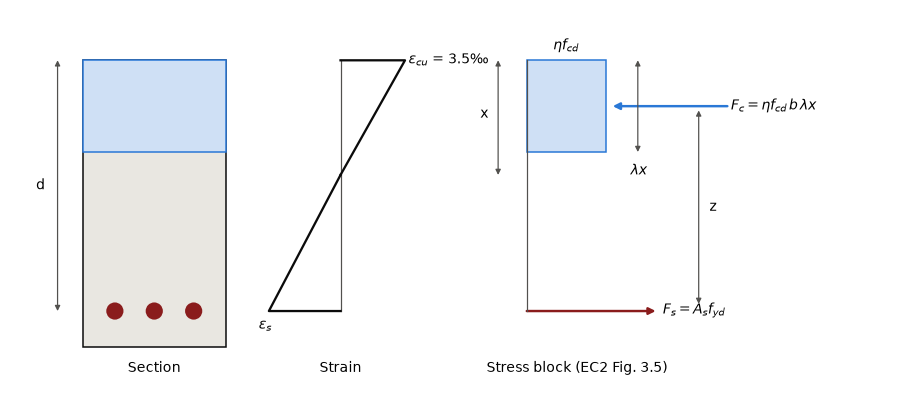

In [2]:
P.sketch_block()

## Derivation: rectangular section, tension steel only

For fck ≤ 50 N/mm² (50 MPa): λ = 0.8 and η = 1.0 (EC2 Exp. 3.19, 3.21).

1. Concrete force $F_c = \eta f_{cd}\, b\, \lambda x$, acting at $\lambda x/2$ below the top, so $z = d - \lambda x/2$.
2. Steel force $F_s = A_s f_{yd}$.
3. Moment equilibrium: $M_{Ed} = F_c z = \eta f_{cd}\, b\, \lambda x\,(d - \lambda x/2)$.
4. Put $\lambda x = 2(d - z)$ and $K = M_{Ed}/(b d^2 f_{ck})$:

$$K = \frac{2\eta f_{cd}}{f_{ck}}\left(1-\frac{z}{d}\right)\frac{z}{d} \;\Rightarrow\; \boxed{z = \frac d2\left[1+\sqrt{1-\frac{2K f_{ck}}{\eta f_{cd}}}\right]}$$

With $f_{cd} = 0.85f_{ck}/1.5 = 0.567f_{ck}$ this is the familiar $z = d\,[0.5+\sqrt{0.25-K/1.134}]$.

5. $\boxed{A_s = M_{Ed}/(f_{yd}\,z)}$ with $f_{yd} = f_{yk}/1.15 = 0.87f_{yk}$.

The limit z ≤ 0.95d comes from BS 8110-1 3.4.4.4. It is not an EC2 rule, and is kept because it is conservative.

## Limit on the neutral axis: K′

Ductility and redistribution (EC2 5.5(4)): $\delta \ge k_1 + k_2\,x_u/d$, so $x_u/d \le (\delta-k_1)/k_2$.

| | k₁ | k₂ | x/d for δ = 1.0 |
|:--|:-:|:-:|:-:|
| EC2 recommended | 0.44 | 1.25 | 0.448 |
| UK NA, fyk ≤ 500 | 0.40 | 1.00 | 0.60 |

This guide never exceeds **x/d = 0.45** (the EC2 5.6.3(2) value), which is tighter than the UK NA limit when δ = 1.0:

$$K' = \frac{\eta f_{cd}}{f_{ck}}\,\lambda\xi\left(1-\frac{\lambda\xi}{2}\right) = 0.567\times0.8\times0.45\,(1-0.18) = \mathbf{0.167}$$

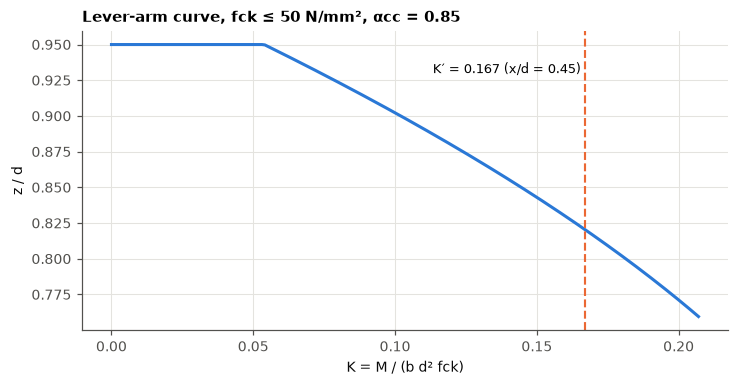

**K′ with moment redistribution (UK NA k₁, k₂; ceiling 0.45)**

| δ | x/d limit | K′ (αcc = 0.85) |
|:--|:-:|:-:|
| 1 | 0.45 | 0.167 |
| 0.9 | 0.45 | 0.167 |
| 0.85 | 0.45 | 0.167 |
| 0.8 | 0.4 | 0.152 |
| 0.75 | 0.35 | 0.136 |
| 0.7 | 0.3 | 0.12 |


In [3]:
P.k_z_chart()
table([[d_, min((d_ - .4) / 1.0, .45), round(.85/1.5 * .8 * min(d_ - .4, .45) * (1 - .4 * min(d_ - .4, .45)), 3)] for d_ in (1.0, .9, .85, .8, .75, .7)], ["δ", "x/d limit", "K′ (αcc = 0.85)"], "K′ with moment redistribution (UK NA k₁, k₂; ceiling 0.45)")

## Doubly reinforced: K > K′

The extra moment is carried by a couple between compression steel and extra tension steel:

$$A_{s2} = \frac{(K-K')f_{ck}bd^2}{f_{s2}(d-d_2)}, \qquad A_s = \frac{K' f_{ck}bd^2}{f_{yd}z} + A_{s2}\frac{f_{s2}}{f_{yd}}$$

Compression steel stress from strain compatibility: $\varepsilon_{s2} = 0.0035\,(x-d_2)/x$ and $f_{s2} = \min(E_s\varepsilon_{s2}, f_{yd})$.
Links must hold compression bars at a spacing ≤ 15φ (EC2 9.2.1.2(3)).

## Flanged sections (EC2 5.3.2.1)

$$b_{eff} = \sum b_{eff,i} + b_w \le b, \qquad b_{eff,i} = 0.2b_i + 0.1l_0 \le 0.2l_0,\; \le b_i$$

$l_0$ = 0.85$l_1$ (end span), 0.7$l_2$ (interior span), 0.15($l_1+l_2$) (over an interior support): EC2 Fig. 5.2.

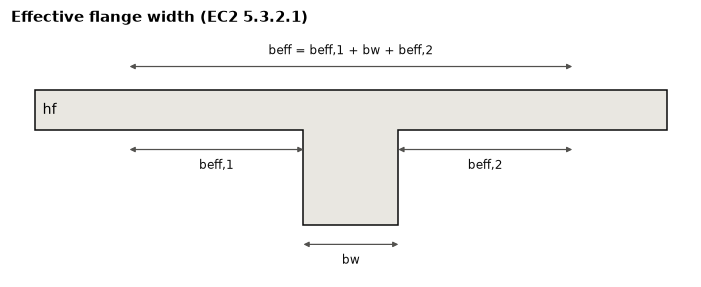

In [4]:
P.sketch_flange()

If $M_{Ed} \le \eta f_{cd}b_{eff}h_f(d-h_f/2)$ the stress block stays in the flange: design as a rectangle of width $b_{eff}$.
Otherwise split the moment between the flange outstands and the web.

## Limits (EC2 9.2.1.1)

$A_{s,min} = \max(0.26\,f_{ctm}/f_{yk}\,b_t d;\; 0.0013\,b_t d)$ and $A_{s,max} = 0.04A_c$.

## Worked example A: singly reinforced

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `M` | Design moment (ULS) | kN·m | > 0 |
| `b`, `h`, `d` | Width, depth, effective depth | mm | d < h |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |
| `n`, `phi` | Number and size of bars to verify | mm | 8, 10, 12, 16, 20, 25, 32 |
| `link`, `cover` | Link size, cover to the link | mm |  |

In [5]:
# INPUTS: edit only this cell, then run the cells below it
A = dict(M=150, b=300, h=500, d=450, fck=30, fyk=500,      # kN·m, mm, N/mm²
         n=3, phi=20, link=8, cover=30)                    # bars to verify

In [6]:
s = Sheet("Singly reinforced section", element=f"{A['b']} × {A['h']}, M = {A['M']} kN·m")
D.materials(s, A["fck"], A["fyk"], BRIEF["ndp"])
D.flexure(s, A["M"], A["b"], A["d"]); s.show("Bending")
s.let("h", A["h"], "mm"); D.beam_bars(s, A["n"], A["phi"], A["b"], A["cover"], A["link"]); s.show("Bars"); s.summary()

## Singly reinforced section

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* 300 × 500, M = 150 kN·m

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Bending

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 Exp. (3.21) | Stress-block strength factor, fck ≤ 50: $\eta$ | $\eta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | Design moment: $M_{Ed}$ | $M_{Ed} = 150$ kN·m |
|  | $b$ | $b = 300$ mm |
|  | Effective depth: $d$ | $d = 450$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{150\times 10^{6}}{300\times 450^{2}\times 30}$ | $\mathbf{K = 0.0823}$ |
| EC2 5.5(4) | **Check:** singly reinforced<br>$K = 0.0823 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.49 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{450}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.0823\times 30}{1\times 17}}\right);\; 0.95\times 450\right\}$ | $\mathbf{z = 414.5}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(450 - 414.5\right)}{0.8}$ | $\mathbf{x = 88.69}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{150\times 10^{6}}{434.8\times 414.5}$ | $\mathbf{A_{s,req} = 832.3}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 300$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 300\times 450;\; 0.0013\times 300\times 450\right\}$ | $\mathbf{A_{s,min} = 203.3}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{832.3;\; 203.3\right\}$ | $\mathbf{A_{s,req} = 832.3}$ mm² |


### Bars

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $h$ | $h = 500$ mm |
|  | Number of bars: $n_{bars}$ | $n_{bars} = 3$  |
|  | $\phi$ | $\phi = 20$ mm |
|  | $A_{s,prov} = \dfrac{n_{bars}\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{3\times \pi\times 20^{2}}{4}$ | $\mathbf{A_{s,prov} = 942.5}$ mm² |
| EC2 6.1, 9.2.1.1 | **Check:** area provided<br>$A_{s,prov} = 942.5 \ge A_{s,req} = 832.3$ mm² | ✅ **PASS**<br>ratio 0.88 |
|  | $b_{w}$ | $b_{w} = 300$ mm |
|  | $c_{nom}$ | $c_{nom} = 30$ mm |
|  | $\phi_{link}$ | $\phi_{link} = 8$ mm |
|  | Maximum aggregate size (project input): $d_{g}$ | $d_{g} = 20$ mm |
|  | Bars in one layer: $n_{layer}$ | $n_{layer} = 3$  |
|  | $s_{clear} = \dfrac{b_{w} - 2\,c_{nom} - 2\,\phi_{link} - n_{layer}\,\phi}{n_{layer} - 1}$<br>$\quad = \dfrac{300 - 2\times 30 - 2\times 8 - 3\times 20}{3 - 1}$ | $\mathbf{s_{clear} = 82}$ mm |
| EC2 8.2(2), k₁ = 1, k₂ = 5 mm | $s_{min} = \max\left\{\phi;\; d_{g} + 5;\; 20\right\}$<br>$\quad = \max\left\{20;\; 20 + 5;\; 20\right\}$ | $\mathbf{s_{min} = 25}$ mm |
| EC2 8.2(2) | **Check:** clear bar spacing<br>$s_{clear} = 82 \ge s_{min} = 25$ mm | ✅ **PASS**<br>ratio 0.30 |
| EC2 9.2.1.1(3) | $A_{s,max} = 0.04\,b_{w}\,h$<br>$\quad = 0.04\times 300\times 500$ | $\mathbf{A_{s,max} = 6000}$ mm² |
| EC2 9.2.1.1(3) | **Check:** maximum steel<br>$A_{s,prov} = 942.5 \le A_{s,max} = 6000$ mm² | ✅ **PASS**<br>ratio 0.16 |
|  | **PROVIDE: 3H20  (942 mm²)** | 🟦 **3H20  (942 mm²)** |


### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| singly reinforced | EC2 5.5(4) | 0.49 | ✅ PASS |
| area provided | EC2 6.1, 9.2.1.1 | 0.88 | ✅ PASS |
| clear bar spacing | EC2 8.2(2) | 0.30 | ✅ PASS |
| maximum steel | EC2 9.2.1.1(3) | 0.16 | ✅ PASS |

**All checks pass.**

## Worked example B: doubly reinforced

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `M` | Design moment (ULS) | kN·m | > 0 |
| `b`, `h`, `d` | Width, depth, effective depth | mm | d < h |
| `d2` | Depth to the compression steel | mm | less than d |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |

Compression steel is designed only if K > K′.

In [7]:
# INPUTS: edit only this cell, then run the cells below it
Bx = dict(M=380, b=300, h=500, d=440, d2=50, fck=30, fyk=500)      # kN·m, mm, N/mm²

In [8]:
s = Sheet("Doubly reinforced section", element=f"{Bx['b']} × {Bx['h']}, M = {Bx['M']} kN·m")
D.materials(s, Bx["fck"], Bx["fyk"], BRIEF["ndp"], show=False); s.rows = []
D.flexure(s, Bx["M"], Bx["b"], Bx["d"], d2=Bx["d2"]); s.show("Bending"); s.summary()

## Doubly reinforced section

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* 300 × 500, M = 380 kN·m

### Bending

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 Exp. (3.21) | Stress-block strength factor, fck ≤ 50: $\eta$ | $\eta = 1$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | Design moment: $M_{Ed}$ | $M_{Ed} = 380$ kN·m |
|  | $b$ | $b = 300$ mm |
|  | Effective depth: $d$ | $d = 440$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{380\times 10^{6}}{300\times 440^{2}\times 30}$ | $\mathbf{K = 0.218}$ |
| EC2 6.1 | K > K′ so compression reinforcement is required. |  |
|  | Depth to compression steel: $d_{2}$ | $d_{2} = 50$ mm |
|  | $x = \xi_{lim}\,d$<br>$\quad = 0.45\times 440$ | $\mathbf{x = 198}$ mm |
|  | $z = d - \dfrac{\lambda\,x}{2}$<br>$\quad = 440 - \dfrac{0.8\times 198}{2}$ | $\mathbf{z = 360.8}$ mm |
| EC2 6.1(2)P, Table 3.1 | Compression steel strain<br>$\varepsilon_{s2} = \dfrac{0.0035\,\left(x - d_{2}\right)}{x}$<br>$\quad = \dfrac{0.0035\times \left(198 - 50\right)}{198}$ | $\mathbf{\varepsilon_{s2} = 0.00262}$ |
| EC2 Fig. 3.8 | $f_{s2} = \min\left\{E_{s}\,\varepsilon_{s2};\; f_{yd}\right\}$<br>$\quad = \min\left\{200000\times 0.00262;\; 434.8\right\}$ | $\mathbf{f_{s2} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 6.1 (Notebook 2.2) | $A_{s2,req} = \dfrac{\left(K - K'\right)\,f_{ck}\,b\,d^{2}}{f_{s2}\,\left(d - d_{2}\right)}$<br>$\quad = \dfrac{\left(0.218 - 0.167\right)\times 30\times 300\times 440^{2}}{434.8\times \left(440 - 50\right)}$ | $\mathbf{A_{s2,req} = 522.1}$ mm² |
| EC2 6.1 (Notebook 2.2) | $A_{s,req} = \dfrac{K'\,f_{ck}\,b\,d^{2}}{f_{yd}\,z} + \dfrac{A_{s2,req}\,f_{s2}}{f_{yd}}$<br>$\quad = \dfrac{0.167\times 30\times 300\times 440^{2}}{434.8\times 360.8} + \dfrac{522.1\times 434.8}{434.8}$ | $\mathbf{A_{s,req} = 2380.1}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 300$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 300\times 440;\; 0.0013\times 300\times 440\right\}$ | $\mathbf{A_{s,min} = 198.8}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{2380.1;\; 198.8\right\}$ | $\mathbf{A_{s,req} = 2380.1}$ mm² |


### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|


**All checks pass.**

## Worked example C: flanged section, block in the flange, then in the web

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `M` | Design moments (ULS) | kN·m | `(400, 780)`; for one value write `(400,)` |
| `beff`, `bw` | Effective flange width, web width | mm | beff ≥ bw |
| `hf`, `d` | Flange thickness, effective depth | mm | hf < d |
| `fck`, `fyk` | Concrete and steel strength | N/mm² | 12 to 50; 400 to 600 |

In [9]:
# INPUTS: edit only this cell, then run the cells below it
T = dict(M=(400, 780), beff=1200, bw=300, hf=120, d=540, fck=30, fyk=500)      # two moments (kN·m), mm, N/mm²

In [10]:
s = Sheet("T-section", element=f"beff = {T['beff']}, bw = {T['bw']}, hf = {T['hf']}")
D.materials(s, T["fck"], T["fyk"], BRIEF["ndp"], show=False); s.rows = []
for M in T["M"]:
    D.flexure_flanged(s, M, T["beff"], T["bw"], T["hf"], T["d"]); s.show(f"M = {M} kN·m")
s.summary()

## T-section

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* beff = 1200, bw = 300, hf = 120

### M = 400 kN·m

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Exp. (3.21) | $\eta$ | $\eta = 1$  |
|  | Design moment: $M_{Ed}$ | $M_{Ed} = 400$ kN·m |
| EC2 5.3.2.1 | Effective flange width: $b_{eff}$ | $b_{eff} = 1200$ mm |
|  | Flange thickness: $h_{f}$ | $h_{f} = 120$ mm |
|  | $d$ | $d = 540$ mm |
| EC2 3.1.7(3) | Moment capacity with the stress block filling the flange<br>$M_{Rd,f} = \dfrac{\eta\,f_{cd}\,b_{eff}\,h_{f}\,\left(d - \dfrac{h_{f}}{2}\right)}{10^{6}}$<br>$\quad = \dfrac{1\times 17\times 1200\times 120\times \left(540 - \dfrac{120}{2}\right)}{10^{6}}$ | $\mathbf{M_{Rd,f} = 1175}$ kN·m |
| EC2 3.1.7(3) | **Check:** stress block within flange<br>$M_{Ed} = 400 \le M_{Rd,f} = 1175$ kN·m | ✅ **PASS**<br>ratio 0.34 |
| EC2 5.5(4) | Redistributed / elastic moment: $\delta$ | $\delta = 1$  |
| EC2 5.5(4), NA | UK National Annex: $k_{1}$ | $k_{1} = 0.4$  |
| EC2 5.5(4), NA | UK National Annex: $k_{2}$ | $k_{2} = 1$  |
| EC2 Exp. (3.19) | Stress-block depth factor, fck ≤ 50: $\lambda$ | $\lambda = 0.8$  |
| EC2 5.5(4), 5.6.3(2) | x/d limit. The 0.45 ceiling is the EC2 5.6.3(2) ductility value, kept for every section<br>$\xi_{lim} = \min\left\{\dfrac{\delta - k_{1}}{k_{2}};\; 0.45\right\}$<br>$\quad = \min\left\{\dfrac{1 - 0.4}{1};\; 0.45\right\}$ | $\mathbf{\xi_{lim} = 0.45}$ |
| EC2 3.1.7(3) (Notebook 2.2) | $K' = \dfrac{\eta\,f_{cd}}{f_{ck}}\,\lambda\,\xi_{lim}\,\left(1 - \dfrac{\lambda\,\xi_{lim}}{2}\right)$<br>$\quad = \dfrac{1\times 17}{30}\times 0.8\times 0.45\times \left(1 - \dfrac{0.8\times 0.45}{2}\right)$ | $\mathbf{K' = 0.167}$ |
|  | $b$ | $b = 1200$ mm |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{400\times 10^{6}}{1200\times 540^{2}\times 30}$ | $\mathbf{K = 0.0381}$ |
| EC2 5.5(4) | **Check:** singly reinforced<br>$K = 0.0381 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.23 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{540}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.0381\times 30}{1\times 17}}\right);\; 0.95\times 540\right\}$ | $\mathbf{z = 513}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(540 - 513\right)}{0.8}$ | $\mathbf{x = 67.5}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{400\times 10^{6}}{434.8\times 513}$ | $\mathbf{A_{s,req} = 1793.4}$ mm² |
|  | Mean width of the tension zone: $b_{t}$ | $b_{t} = 300$ mm |
| EC2 Exp. (9.1N) | $A_{s,min} = \max\left\{\dfrac{0.26\,f_{ctm}}{f_{yk}}\,b_{t}\,d;\; 0.0013\,b_{t}\,d\right\}$<br>$\quad = \max\left\{\dfrac{0.26\times 2.896}{500}\times 300\times 540;\; 0.0013\times 300\times 540\right\}$ | $\mathbf{A_{s,min} = 244}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{1793.4;\; 244\right\}$ | $\mathbf{A_{s,req} = 1793.4}$ mm² |


### M = 780 kN·m

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Design moment: $M_{Ed}$ | $M_{Ed} = 780$ kN·m |
| EC2 3.1.7(3) | **Check:** stress block within flange<br>$M_{Ed} = 780 \le M_{Rd,f} = 1175$ kN·m | ✅ **PASS**<br>ratio 0.66 |
| EC2 3.1.7(3), 6.1 (Notebook 2.2) | $K = \dfrac{M_{Ed}\times 10^{6}}{b\,d^{2}\,f_{ck}}$<br>$\quad = \dfrac{780\times 10^{6}}{1200\times 540^{2}\times 30}$ | $\mathbf{K = 0.0743}$ |
| EC2 5.5(4) | **Check:** singly reinforced<br>$K = 0.0743 \le K' = 0.167$  | ✅ **PASS**<br>ratio 0.44 |
| EC2 3.1.7(3) (Notebook 2.2); 0.95d: BS 8110-1 3.4.4.4 | Lever arm<br>$z = \min\left\{\dfrac{d}{2}\,\left(1 + \sqrt{1 - \dfrac{2\,K\,f_{ck}}{\eta\,f_{cd}}}\right);\; 0.95\,d\right\}$<br>$\quad = \min\left\{\dfrac{540}{2}\times \left(1 + \sqrt{1 - \dfrac{2\times 0.0743\times 30}{1\times 17}}\right);\; 0.95\times 540\right\}$ | $\mathbf{z = 501.9}$ mm |
|  | Neutral axis depth<br>$x = \dfrac{2\,\left(d - z\right)}{\lambda}$<br>$\quad = \dfrac{2\times \left(540 - 501.9\right)}{0.8}$ | $\mathbf{x = 95.22}$ mm |
| EC2 6.1 | $A_{s,req} = \dfrac{M_{Ed}\times 10^{6}}{f_{yd}\,z}$<br>$\quad = \dfrac{780\times 10^{6}}{434.8\times 501.9}$ | $\mathbf{A_{s,req} = 3574.3}$ mm² |
| EC2 9.2.1.1(1) | Area to provide<br>$A_{s,req} = \max\left\{A_{s,req};\; A_{s,min}\right\}$<br>$\quad = \max\left\{3574.3;\; 244\right\}$ | $\mathbf{A_{s,req} = 3574.3}$ mm² |


### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| stress block within flange | EC2 3.1.7(3) | 0.34 | ✅ PASS |
| singly reinforced | EC2 5.5(4) | 0.23 | ✅ PASS |
| stress block within flange | EC2 3.1.7(3) | 0.66 | ✅ PASS |
| singly reinforced | EC2 5.5(4) | 0.44 | ✅ PASS |

**All checks pass.**